# 16 — Dual-pol entropy / anisotropy / α (Cloude 2007)

**Goal:** apply the eigen-decomposition of C2: entropy **H** (0 = one pure mechanism, 1 = fully
random), anisotropy **A** = (λ1 − λ2)/(λ1 + λ2), and mean scattering angle **ᾱ** (0° = co-pol
dominated, 90° = cross-pol dominated), then read the H–α plane, before and after the clear-cut.

With dual-pol, α and H describe the **HH/HV** balance only; the quad-pol H–α zones of Cloude &
Pottier (1997) do not apply as such. Dual-pol H–α is used for vegetation/soil discrimination
(Cloude 2007; Ji & Wu 2015).

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "16"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})
import h5py
from nisar_s1 import polarimetry as pol
from nisar_s1.grid import polygon_mask
from nisar_s1.optical import Raster
from affine import Affine
import geopandas as gpd
session = P.load_session(kit["session_file"], required=("gslc_subsets", "c2_looks"))
looks = tuple(session["c2_looks"])

In [2]:
def c2_of(path):
    with h5py.File(path) as h5:
        g = P.product_profile(h5).grids["frequencyA"]
        win = P.window_from_bounds(g, g.bounds)
        c = pol.c2_from_slc(P.read_layer(h5, g, "HH", win), P.read_layer(h5, g, "HV", win), looks)
    return c, win.transform @ Affine.scale(looks[1], looks[0]), win.crs

res = {}
for i, (k, p) in enumerate(zip(["pre (18 Jul)", "post (23 Aug)"], session["gslc_subsets"][:2]), 1):
    c, tr, crs = c2_of(p)
    res[k] = pol.h_alpha_dual(c); res[k]["tr"] = tr; res[k]["crs"] = crs
    print(f"[{i}/2] {k}: median H = {np.nanmedian(res[k]['H']):.2f}, median α = {np.nanmedian(res[k]['alpha']):.1f}°")

[1/2] pre (18 Jul): median H = 0.77, median α = 26.3°


[2/2] post (23 Aug): median H = 0.73, median α = 23.8°


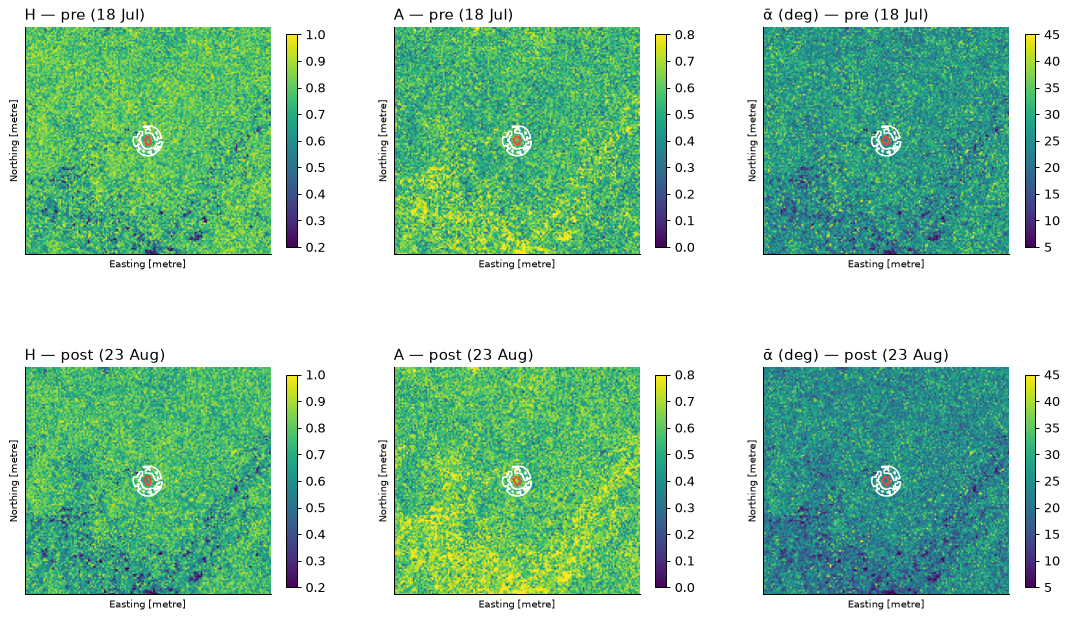

In [3]:
sites = gpd.read_file(kit["aoi"]["site_polygons"]).to_crs(res["pre (18 Jul)"]["crs"])
fig, axs = plt.subplots(2, 3, figsize=(15, 9))
for row, (k, r) in zip(axs, res.items()):
    ny, nx = r["H"].shape; tr = r["tr"]
    ext = [tr.c, tr.c + tr.a * nx, tr.f + tr.e * ny, tr.f]
    for ax, (v, lim, t) in zip(row, [("H", (0.2, 1), "H"), ("A", (0, 0.8), "A"), ("alpha", (5, 45), "ᾱ (deg)")]):
        im = ax.imshow(r[v], vmin=lim[0], vmax=lim[1], cmap="viridis", extent=ext)
        sites.boundary.plot(ax=ax, color=["#ff4136" if s == "cut" else "white" for s in sites.role], lw=1.2)
        ax.set_title(f"{t} — {k}", loc="left"); ax.set_xticks([]); ax.set_yticks([]); plt.colorbar(im, ax=ax, shrink=0.75)
fig.savefig(OUT / "16_h_a_alpha.png", dpi=100, bbox_inches="tight"); plt.show()

## H–α plane, cut versus control forest

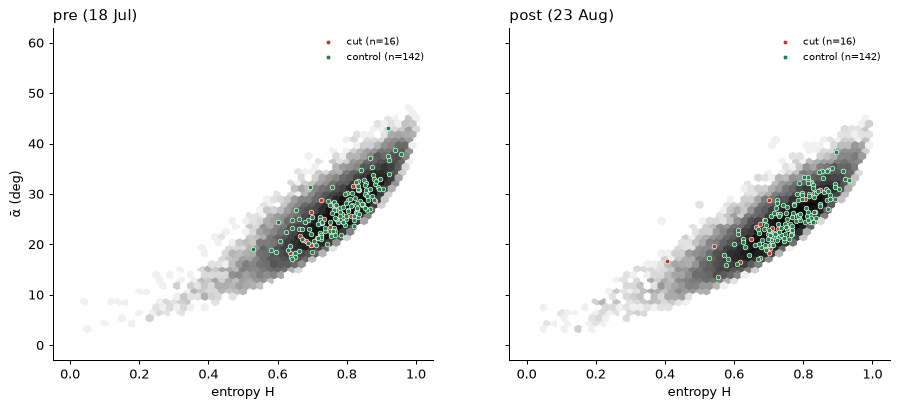

,date,unit,n,H,A,alpha
0,pre (18 Jul),cut,16,0.729,0.593,24.198999
1,pre (18 Jul),control,142,0.782,0.536,26.204000
2,post (23 Aug),cut,16,0.702,0.620,22.667999
3,post (23 Aug),control,142,0.765,0.555,24.938999


In [4]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
table = []
for ax, (k, r) in zip(axs, res.items()):
    ref = Raster(r["H"], r["tr"], r["crs"])
    ax.hexbin(r["H"].ravel(), r["alpha"].ravel(), gridsize=50, bins="log", cmap="Greys", extent=(0, 1, 0, 60))
    for _, s in sites.iterrows():
        m = polygon_mask([s.geometry], ref) & np.isfinite(r["H"])
        c = "#c0392b" if s.role == "cut" else "#1e8449"
        ax.scatter(r["H"][m], r["alpha"][m], s=14, color=c, edgecolor="white", lw=0.5, label=f"{s.role} (n={m.sum()})")
        table.append({"date": k, "unit": s.role, "n": int(m.sum()), "H": np.nanmedian(r["H"][m]),
                      "A": np.nanmedian(r["A"][m]), "alpha": np.nanmedian(r["alpha"][m])})
    ax.set_xlabel("entropy H"); ax.set_title(k, loc="left"); ax.legend(frameon=False, fontsize=8)
axs[0].set_ylabel("ᾱ (deg)"); fig.savefig(OUT / "16_h_alpha_plane.png", dpi=110, bbox_inches="tight"); plt.show()
ha = pd.DataFrame(table).round(3); ha

**Reading.** Before the cut, both units are forest: high entropy (≈ 0.75) and ᾱ ≈ 25°, well
above the meadows of the valley. After the cut, the cut moves only **slightly** towards lower H and
lower ᾱ, while its HV power dropped by ~4 dB (notebook 11). At L-band the logged stand still
depolarizes (stumps, slash, regrowth, rough soil): the *ratio* HV/HH changes little even though both
powers fall. Dual-pol H/α is therefore a weak clear-cut indicator here — the power is the signal.
With a 2.4 ha cut there are only ~16 pixels at 40 m: an illustration, not a statistical test (19).

In [5]:
np.savez_compressed(OUT / "h_alpha.npz", **{f"{k.split()[0]}_{v}": res[k][v] for k in res for v in ("H", "A", "alpha")})

In [6]:
checks = {
    "H within [0, 1]": all(np.nanmax(r['H']) <= 1 + 1e-5 for r in res.values()),
    "alpha within [0, 90]": all(np.nanmax(r['alpha']) <= 90 for r in res.values()),
    "both units sampled": (ha.n > 0).all(),
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 16 STATUS: PASS")

  [x] H within [0, 1]
  [x] alpha within [0, 90]
  [x] both units sampled
Module 16 STATUS: PASS
